In [4]:
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from sklearn.metrics import (ConfusionMatrixDisplay, classification_report,
                             RocCurveDisplay, precision_recall_curve,
                             precision_score, recall_score, f1_score)

X_test = pd.read_csv("../data/processed/X_test.csv")
y_test = pd.read_csv("../data/processed/y_test.csv")["defect"]

models = {
    "Logistic Regression": joblib.load("../models/logistic_regression.joblib"),
    "Random Forest": joblib.load("../models/random_forest.joblib"),
    "XGBoost": joblib.load("../models/xgboost.joblib"),
}
lr = models["Logistic Regression"]
print(X_test.shape, y_test.shape)

(400, 12) (400,)


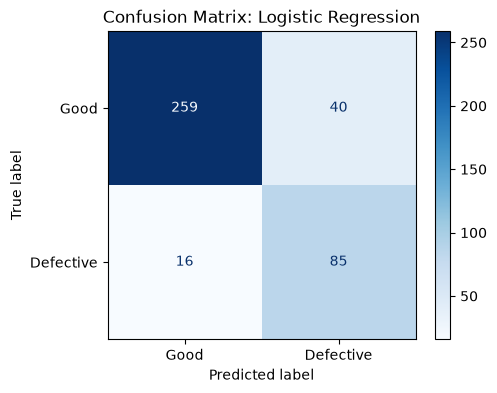

In [5]:
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_estimator(
    lr, X_test, y_test,
    display_labels=["Good", "Defective"], cmap="Blues", ax=ax)
plt.title("Confusion Matrix: Logistic Regression")
plt.savefig("../reports/08_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
print(classification_report(y_test, lr.predict(X_test),
                            target_names=["Good", "Defective"]))

              precision    recall  f1-score   support

        Good       0.94      0.87      0.90       299
   Defective       0.68      0.84      0.75       101

    accuracy                           0.86       400
   macro avg       0.81      0.85      0.83       400
weighted avg       0.88      0.86      0.86       400



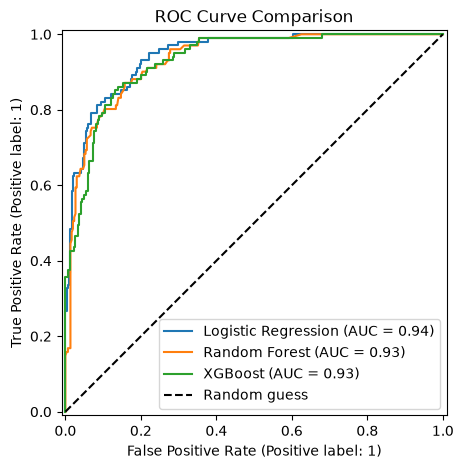

In [7]:
fig, ax = plt.subplots(figsize=(6, 5))
for name, model in models.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="Random guess")
ax.set_title("ROC Curve Comparison")
ax.legend()
plt.savefig("../reports/09_roc_curves.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
y_prob = lr.predict_proba(X_test)[:, 1]

rows = []
for t in np.arange(0.2, 0.85, 0.05):
    y_pred_t = (y_prob >= t).astype(int)
    rows.append({
        "Threshold": round(t, 2),
        "Precision": precision_score(y_test, y_pred_t),
        "Recall": recall_score(y_test, y_pred_t),
        "F1": f1_score(y_test, y_pred_t),
        "Flagged parts": y_pred_t.sum(),
    })

thr_df = pd.DataFrame(rows).round(3)
thr_df

,Threshold,Precision,Recall,F1,Flagged parts
0,0.20,0.544,0.970,0.698,180
1,0.25,0.564,0.960,0.711,172
2,0.30,0.590,0.941,0.725,161
3,0.35,0.615,0.901,0.731,148
4,0.40,0.627,0.881,0.733,142
5,0.45,0.637,0.851,0.729,135
6,0.50,0.680,0.842,0.752,125
7,0.55,0.712,0.832,0.767,118
8,0.60,0.777,0.792,0.784,103
9,0.65,0.796,0.772,0.784,98


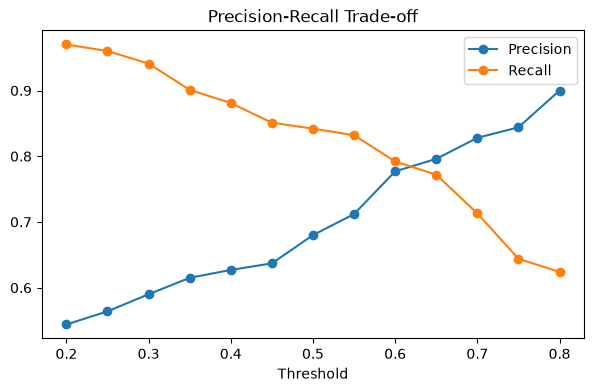

In [9]:
plt.figure(figsize=(7, 4))
plt.plot(thr_df["Threshold"], thr_df["Precision"], marker="o", label="Precision")
plt.plot(thr_df["Threshold"], thr_df["Recall"], marker="o", label="Recall")
plt.xlabel("Threshold")
plt.title("Precision-Recall Trade-off")
plt.legend()
plt.savefig("../reports/10_threshold_tradeoff.png", dpi=150, bbox_inches="tight")
plt.show()

In [14]:
# ASSUMPTIONS 
COST_MISSED_DEFECT = 2000   # ₹ per defective part reached customer
COST_FALSE_ALARM   = 500    # ₹ per good part unnecessarily inspected

costs = []
for t in np.arange(0.1, 0.9, 0.05):
    y_pred_t = (y_prob >= t).astype(int)
    fn = ((y_pred_t == 0) & (y_test == 1)).sum()
    fp = ((y_pred_t == 1) & (y_test == 0)).sum()
    costs.append({"Threshold": round(t, 2), "Missed (FN)": fn, "False alarms (FP)": fp,
                  "Total cost ₹": fn * COST_MISSED_DEFECT + fp * COST_FALSE_ALARM})

cost_df = pd.DataFrame(costs)
best = cost_df.loc[cost_df["Total cost ₹"].idxmin()]
print(cost_df)
print("\n Best threshold:", best["Threshold"], "| Min cost: ₹", best["Total cost ₹"])

    Threshold  Missed (FN)  False alarms (FP)  Total cost ₹
0        0.10            1                123         63500
1        0.15            2                101         54500
2        0.20            3                 82         47000
3        0.25            4                 75         45500
4        0.30            6                 66         45000
5        0.35           10                 57         48500
6        0.40           12                 53         50500
7        0.45           15                 49         54500
8        0.50           16                 40         52000
9        0.55           17                 34         51000
10       0.60           21                 23         53500
11       0.65           23                 20         56000
12       0.70           29                 15         65500
13       0.75           36                 12         78000
14       0.80           38                  7         79500
15       0.85           47              